<a href="https://colab.research.google.com/github/HafizRizqi/MachineLearning_2026/blob/main/JS08/JS08_01.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 🥇Lab 1
Hierarchical Clustering

Langkah 0 - Download Dataset

In [13]:
from google.colab import files
uploaded = files.upload()

Saving Mall_Customers.csv to Mall_Customers (1).csv


Langkah 1 - Import Library

In [14]:
	import numpy as np
	import matplotlib.pyplot as plt
	import pandas as pd

Langkah 2 - Load Dataset

In [15]:
	# Load dataset
	df = pd.read_csv('Mall_Customers.csv')

	# Inspect info
	df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype 
---  ------                  --------------  ----- 
 0   CustomerID              200 non-null    int64 
 1   Genre                   200 non-null    object
 2   Age                     200 non-null    int64 
 3   Annual Income (k$)      200 non-null    int64 
 4   Spending Score (1-100)  200 non-null    int64 
dtypes: int64(4), object(1)
memory usage: 7.9+ KB


Langkah 3 - Slicing Fitur

 proses slicing untuk menggunakan fitur Annual Income dan Spending Score saja.




In [16]:
	# Slicing - Select Annual Income and Spending Score only
	X = df.iloc[:, [3, 4]].values # property values will take only the 'values' -> return in ndarray

Langkah 4 - Visualisasi Dendogram

Untuk mempermudah penentuan cluster, kita akan membuat visualisasi dendogram. Visualisasi ini dapat dimanfaatkan untuk menentukan jumlah cluster. Nilai threshold pada sumbu x digunakan untuk menentukan jumlah cluster berdasarkan dendogram.

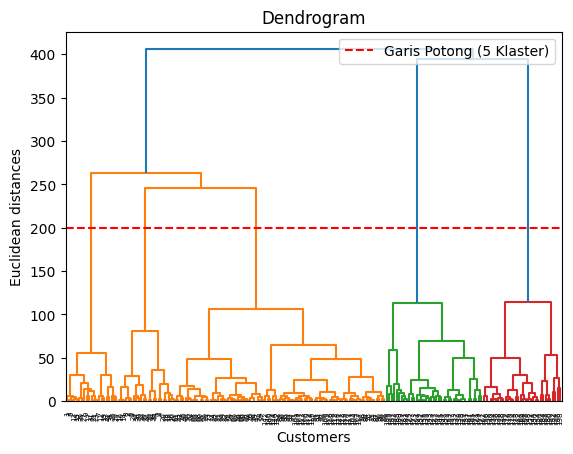

In [28]:
import scipy.cluster.hierarchy as sch
import matplotlib.pyplot as plt

# Build dendrogram using ward distance
dendrogram = sch.dendrogram(sch.linkage(X, method = 'ward'))

# Menambahkan garis potong horizontal pada jarak Euclidean = 200
plt.axhline(y=200, color='red', linestyle='--', label='Garis Potong (5 Klaster)')

# Plot
plt.title('Dendrogram')
plt.xlabel('Customers')
plt.ylabel('Euclidean distances')
plt.legend()
plt.show()

Langkah 5 - Membuat Model Agglomerative

Buat cluster dengan menggunakan model Agglomeratvie (bottom-up) dengan jumlah 5 cluster.

In [32]:
	# Build Cluster using Agglomerative Method
	from sklearn.cluster import AgglomerativeClustering
	hc = AgglomerativeClustering(n_clusters = 5, metric = 'euclidean', linkage = 'ward')
	y_hc = hc.fit_predict(X)

Langkah 6 - Visualisasi Cluster

Untuk mengetahui hasil cluster, visualisasikan cluster dengan menggunakan scatterplot.

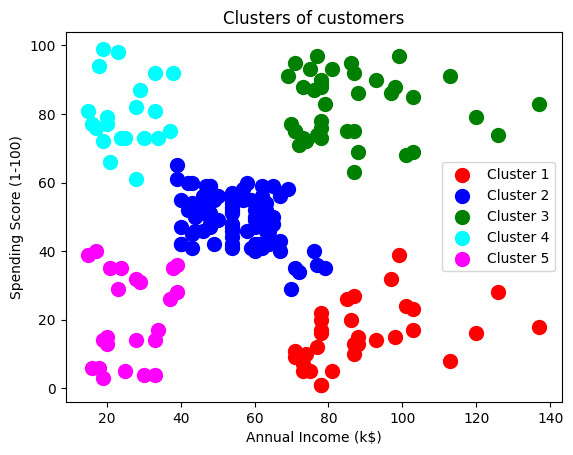

In [33]:
	# Visualize The Result
	plt.scatter(X[y_hc == 0, 0], X[y_hc == 0, 1], s = 100, c = 'red', label = 'Cluster 1')
	plt.scatter(X[y_hc == 1, 0], X[y_hc == 1, 1], s = 100, c = 'blue', label = 'Cluster 2')
	plt.scatter(X[y_hc == 2, 0], X[y_hc == 2, 1], s = 100, c = 'green', label = 'Cluster 3')
	plt.scatter(X[y_hc == 3, 0], X[y_hc == 3, 1], s = 100, c = 'cyan', label = 'Cluster 4')
	plt.scatter(X[y_hc == 4, 0], X[y_hc == 4, 1], s = 100, c = 'magenta', label = 'Cluster 5')
	plt.title('Clusters of customers')
	plt.xlabel('Annual Income (k$)')
	plt.ylabel('Spending Score (1-100)')
	plt.legend()
	plt.show()

Langkah 7 - Evaluasi Hasil Cluster

In [34]:
	from sklearn.metrics import silhouette_score

	# Evaluate the clustering using silhouette coefficient
	silhouette_avg = silhouette_score(X, y_hc)
	print(f'Silhouette Coefficient: {silhouette_avg}')

Silhouette Coefficient: 0.5529945955148897


Hasil dari silhouette score menunjukkan hasil yang cukup baik dengan nilai berkisar
0.55. Kita dapat bereksperimen dengan mengubah jumlah klaster untuk mengetahui jumlah cluster mana yang terbaik.